# 02 — The Smart Parking product

This notebook runs the same Python modules as the desktop app. It uses original PKLot imagery/labels, actual local model checkpoints, recorded Birmingham history, and a saved snapshot of the separately identified Singapore feed. It never silently downloads files or invents readings.

Detection = locate vehicles. Instance segmentation = predict vehicle pixels. Semantic segmentation = predict parking-region pixels. A configured layout gives stable slot IDs. Occupancy classification = decide whether a slot is occupied. Forecasting = estimate a future count from eligible history.

In [1]:
from pathlib import Path
import sys, json, csv
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/birmingham_split.json').exists())
sys.path.insert(0,str(ROOT/'src'))
from PIL import Image
from IPython.display import display
from smart_parking.layout import load_layout
from smart_parking.vision import VisionEngine
with (ROOT/'data/manifests/pklot_frames.csv').open(encoding='utf-8',newline='') as stream:
    frames=list(csv.DictReader(stream))
frame=next(f for f in frames if f['split']=='test')
image=Image.open(ROOT/frame['image']).convert('RGB')
layout=load_layout(ROOT/frame['layout_path'],image.size)
print('Real source frame:',frame['image'])
print('Source: SRC-DS-001; layout geometry from original PKLot XML, without occupancy answers.')


Real source frame: data/raw/pklot_subset/PKLot/parking1b/cloudy/2013-03-19/2013-03-19_07_45_02.jpg
Source: SRC-DS-001; layout geometry from original PKLot XML, without occupancy answers.


## Run actual detection, instance masks and occupancy

Mask R-CNN uses a ResNet50 backbone pretrained externally on COCO. The slot classifier uses ImageNet ResNet18 features with a linear head trained in this project on real occupied/vacant crops. These training histories are different and must not be confused.

No detection does not automatically mean a vacant space. Conflicting evidence remains yellow/uncertain.

{
  "counts": {
    "occupied": 35,
    "vacant": 2,
    "uncertain": 3,
    "total": 40
  },
  "detected_vehicles": 38,
  "latency_seconds": 5.177953200000047,
  "classifier": "PKLot-trained ResNet18 head"
}


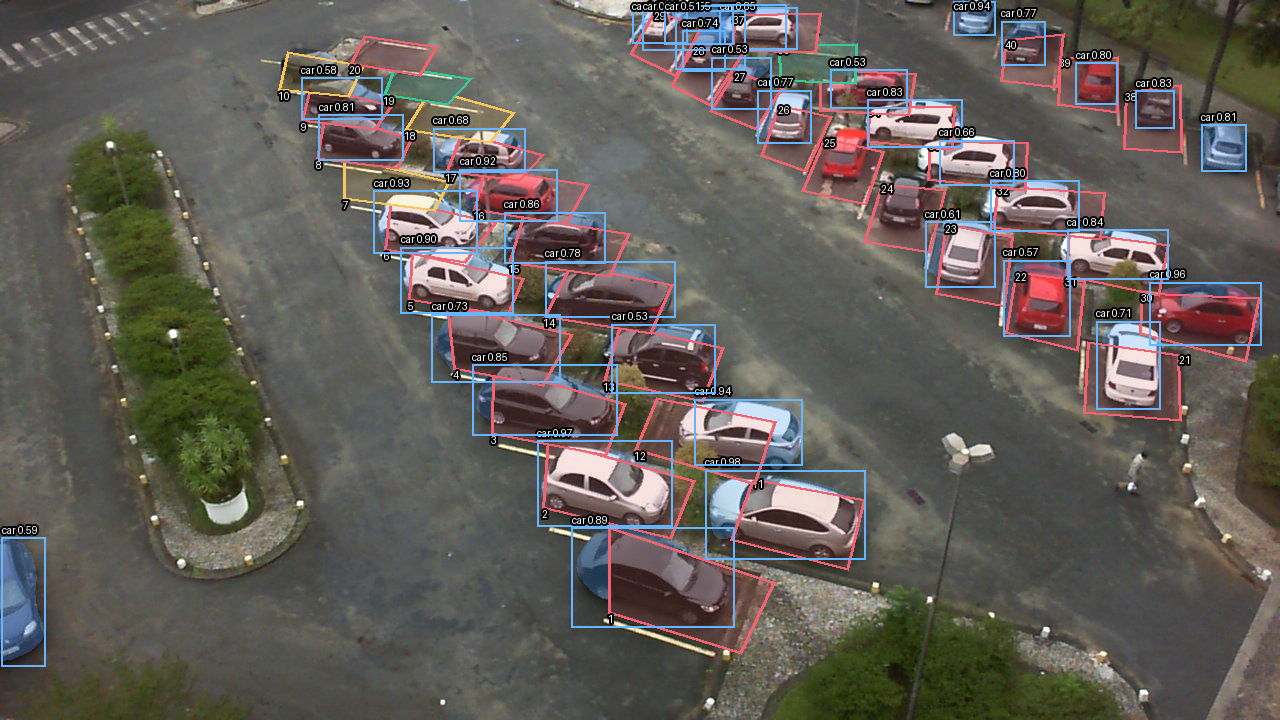

In [2]:
engine=VisionEngine('maskrcnn')
result,overlay=engine.analyze(image,layout,confidence=.5)
print(json.dumps({'counts':result['counts'],'detected_vehicles':len(result['detections']),
                  'latency_seconds':result['latency_seconds'],'classifier':result['classifier']},indent=2))
display(overlay)


## Check the measured classifier and segmentation results

The classifier's held-out score refers to 360 crops from a small convenience subset, not the complete PKLot benchmark. The learned semantic model is experimental and substantially weaker; the reliable identity of each slot comes from the configured layout. Its masks must not be called accurate automatically.

In [3]:
classifier=json.loads((ROOT/'models/vision_model_card.json').read_text())
segmenter=json.loads((ROOT/'models/segmentation_model_card.json').read_text())
print('Classifier:',json.dumps(classifier['classifier_metrics'],indent=2))
print('Experimental semantic segmentation:',json.dumps(segmenter['metrics'],indent=2))


Classifier: {
  "accuracy": 0.9527777777777777,
  "precision": 0.9509433962264151,
  "recall": 0.984375,
  "f1": 0.9673704414587332,
  "confusion_matrix": [
    [
      91,
      13
    ],
    [
      4,
      252
    ]
  ],
  "samples": 360
}
Experimental semantic segmentation: {
  "pixel_iou": 0.25178450033990485,
  "dice": 0.40228090421559975,
  "test_frames": 10
}


## Forecast from genuine historical observations

This trained LSTM is evaluated on Birmingham history. It is not a model for the unrelated PKLot camera or Singapore car parks. The last-observation baseline was better in the first experiment; that limitation remains visible.

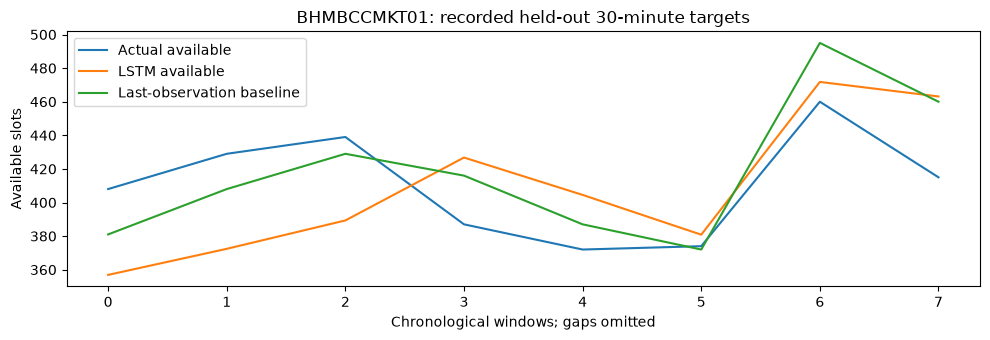

{
  "mae_slots": 121.21014739061688,
  "persistence_mae_slots": 61.142155265399055,
  "normalized_mae": 0.0766560286283493,
  "test_windows": 204,
  "training_seconds": 0.5400235999986762
}


In [4]:
import matplotlib.pyplot as plt
card=json.loads((ROOT/'models/lstm_30min_model_card.json').read_text())
rows=json.loads((ROOT/'experiments/results'/card['run_id']/'test_predictions.json').read_text())
park=rows[0]['car_park_id']; rows=[r for r in rows if r['car_park_id']==park]
fig,ax=plt.subplots(figsize=(10,3.5))
for field,label in [('actual_occupied','Actual available'),('predicted_occupied','LSTM available'),('persistence_occupied','Last-observation baseline')]:
    ax.plot([r['capacity']-r[field] for r in rows],label=label)
ax.set(title=f'{park}: recorded held-out 30-minute targets',xlabel='Chronological windows; gaps omitted',ylabel='Available slots');ax.legend();fig.tight_layout();plt.show()
print(json.dumps(card['metrics'],indent=2))


## Live-data snapshot, honestly labelled

The explicit Refresh control in the desktop app contacts the authorized public HDB/data.gov.sg endpoint, at most once per minute. This notebook defaults to a cached snapshot so it can be rerun offline. A cached snapshot is not automatically current. The provider timestamp and source ID are preserved. No live model forecast is fabricated from an insufficient history.

In [5]:
from smart_parking.live import get_live
rows,metadata=get_live(refresh=False)
print(metadata)
print('Source:',rows[0]['source_id'],'Car parks:',len({r['car_park_id'] for r in rows}))
print('Example actual observation:',rows[0])


{'cached': True, 'path': 'D:\\deep learning\\project001\\data\\raw\\singapore_live\\20261024T091233501553Z.json', 'provider_timestamp': '2026-10-24T17:11:36+08:00'}
Source: SRC-LIVE-001 Car parks: 2005
Example actual observation: {'source_id': 'SRC-LIVE-001', 'car_park_id': 'HE12', 'lot_type': 'C', 'capacity': 105, 'available': 103, 'occupied': 2, 'observed_at': '2026-10-24T17:10:58', 'feed_timestamp': '2026-10-24T17:11:36+08:00'}


## Representative 2D and 3D convolution

A 2D edge kernel acts on this real parking image. A separate explicitly educational numeric volume illustrates 3D convolution over depth and space. The lab compares framework output with handwritten arithmetic. It is not a trained 3D parking model.

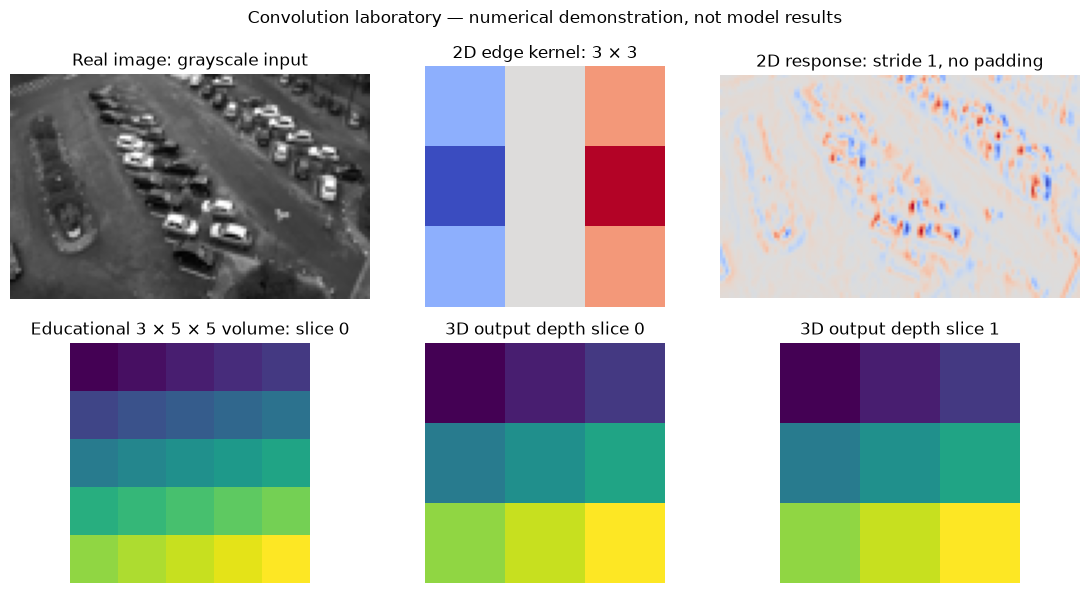

Maximum manual/framework difference: 2.384185791015625e-07 5.960464477539063e-08


In [6]:
from smart_parking.convolution import plot_convolutions
fig,demo=plot_convolutions(image);plt.show()
print('Maximum manual/framework difference:',demo['max_2d_error'],demo['max_3d_error'])


## Trace every result

Original assets: `data/raw/`. Derived crops/history: `data/processed/`. Dataset membership: `data/manifests/` and `data/splits/`. External weights: `models/pretrained/`. Project-trained weights: `models/checkpoints/`. Genuine run outputs: `experiments/results/`. Acquired-asset hashes and timestamps: `data/resource_receipts.jsonl`. See `docs/THIRD_PARTY_SOURCES.md`.

**Practice:** change the detection threshold to 0.7 and explain why the vehicle count can change while the number of configured spaces stays fixed. What does a yellow slot mean? Do not describe raw model scores as calibrated certainty.